In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 

In [2]:
df = pd.read_csv("../results/myministereData.csv")
df = df.drop(columns=["Unnamed: 0" , "USDA Soil Taxonomy"])
df

,X,Y,altitude,UD,LD,average profondeur,pH,CE,A%,L%,S%,ALR(L),ALR(S),OM,CEC
0,1.32,36.20,130.0,0.0,30.0,15.0,7.9,1.4,44.0,13.0,15.0,NaN,NaN,1.3,NaN
1,1.32,36.20,130.0,30.0,75.0,52.5,8.0,0.5,46.0,16.0,15.0,NaN,NaN,1.2,NaN
2,1.32,36.20,130.0,75.0,120.0,97.5,8.0,0.4,46.0,29.0,13.0,NaN,NaN,1.1,NaN
3,1.32,36.20,130.0,120.0,165.0,142.5,8.0,NaN,46.0,27.0,10.0,NaN,NaN,NaN,NaN
4,1.28,38.00,111.0,0.0,30.0,15.0,7.9,1.4,44.0,13.0,15.0,NaN,NaN,1.3,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,1.33,36.20,126.0,70.0,115.0,92.5,NaN,NaN,45.0,9.0,20.0,NaN,NaN,NaN,NaN
80,1.33,36.20,126.0,115.0,140.0,127.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
81,1.33,36.22,154.0,0.0,33.0,16.5,NaN,NaN,31.0,12.0,26.0,NaN,NaN,1.2,NaN
82,1.33,36.22,154.0,33.0,70.0,51.5,NaN,NaN,32.0,10.0,21.0,NaN,NaN,NaN,NaN


In [3]:
import numpy as np
standard_layers = [(0, 5), (5, 15), (15, 30), (30, 60), (60, 100), (100, 200)]
target_columns = ['pH', 'CEC', 'OM', 'A%', 'L%', 'S%', 'ALR(L)', 'ALR(S)', 'CE']
standardized_rows = []
for _, row in df.iterrows():
    ud, ld = row['UD'], row['LD']
    if pd.isnull(ud) or pd.isnull(ld) or ld <= ud:
        continue
    original_thickness = ld - ud
    for std_ud, std_ld in standard_layers:
        overlap_ud = max(ud, std_ud)
        overlap_ld = min(ld, std_ld)
        overlap_thickness = overlap_ld - overlap_ud
        if overlap_thickness <= 0:
            continue
        weight = overlap_thickness / original_thickness
        interpolated_row = {
            'Original_UD': ud,
            'Original_LD': ld,
            'Standard_UD': std_ud,
            'Standard_LD': std_ld,
            'Depth_Mid': (std_ud + std_ld) / 2,
            'Weight': weight
        }
        for col in target_columns:
            interpolated_row[col] = row[col] * weight if not pd.isnull(row[col]) else np.nan
        interpolated_row['X'] = row['X']
        interpolated_row['Y'] = row['Y']
        interpolated_row['altitude'] = row['altitude']
        standardized_rows.append(interpolated_row)

standardized_df = pd.DataFrame(standardized_rows)
standardized_df


,Original_UD,Original_LD,Standard_UD,Standard_LD,Depth_Mid,Weight,pH,CEC,OM,A%,L%,S%,ALR(L),ALR(S),CE,X,Y,altitude
0,0.0,30.0,0,5,2.5,0.166667,1.316667,NaN,0.216667,7.333333,2.166667,2.500000,NaN,NaN,0.233333,1.32,36.20,130.0
1,0.0,30.0,5,15,10.0,0.333333,2.633333,NaN,0.433333,14.666667,4.333333,5.000000,NaN,NaN,0.466667,1.32,36.20,130.0
2,0.0,30.0,15,30,22.5,0.500000,3.950000,NaN,0.650000,22.000000,6.500000,7.500000,NaN,NaN,0.700000,1.32,36.20,130.0
3,30.0,75.0,30,60,45.0,0.666667,5.333333,NaN,0.800000,30.666667,10.666667,10.000000,NaN,NaN,0.333333,1.32,36.20,130.0
4,30.0,75.0,60,100,80.0,0.333333,2.666667,NaN,0.400000,15.333333,5.333333,5.000000,NaN,NaN,0.166667,1.32,36.20,130.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
189,0.0,33.0,30,60,45.0,0.090909,NaN,NaN,0.109091,2.818182,1.090909,2.363636,NaN,NaN,NaN,1.33,36.22,154.0
190,33.0,70.0,30,60,45.0,0.729730,NaN,NaN,NaN,23.351351,7.297297,15.324324,NaN,NaN,NaN,1.33,36.22,154.0
191,33.0,70.0,60,100,80.0,0.270270,NaN,NaN,NaN,8.648649,2.702703,5.675676,NaN,NaN,NaN,1.33,36.22,154.0
192,70.0,115.0,60,100,80.0,0.666667,NaN,NaN,NaN,30.000000,6.000000,13.333333,NaN,NaN,NaN,1.33,36.22,154.0


In [4]:
standardized_df.rename(columns={
    'Standard_UD': 'UD',
    'Standard_LD': 'LD'
}, inplace=True)
standardized_df['average profondeur'] = (standardized_df['UD'] + standardized_df['LD']) / 2
standardized_df['USDA Soil Taxonomy'] = np.nan
final_columns = [
    'X', 'Y', 'altitude', 'UD', 'LD', 'average profondeur', 'USDA Soil Taxonomy',
    'pH', 'CE', 'CEC', 'A%', 'L%', 'S%', 'ALR(L)', 'ALR(S)', 'OM'
]
final_df = standardized_df[final_columns]
final_df

,X,Y,altitude,UD,LD,average profondeur,USDA Soil Taxonomy,pH,CE,CEC,A%,L%,S%,ALR(L),ALR(S),OM
0,1.32,36.20,130.0,0,5,2.5,NaN,1.316667,0.233333,NaN,7.333333,2.166667,2.500000,NaN,NaN,0.216667
1,1.32,36.20,130.0,5,15,10.0,NaN,2.633333,0.466667,NaN,14.666667,4.333333,5.000000,NaN,NaN,0.433333
2,1.32,36.20,130.0,15,30,22.5,NaN,3.950000,0.700000,NaN,22.000000,6.500000,7.500000,NaN,NaN,0.650000
3,1.32,36.20,130.0,30,60,45.0,NaN,5.333333,0.333333,NaN,30.666667,10.666667,10.000000,NaN,NaN,0.800000
4,1.32,36.20,130.0,60,100,80.0,NaN,2.666667,0.166667,NaN,15.333333,5.333333,5.000000,NaN,NaN,0.400000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
189,1.33,36.22,154.0,30,60,45.0,NaN,NaN,NaN,NaN,2.818182,1.090909,2.363636,NaN,NaN,0.109091
190,1.33,36.22,154.0,30,60,45.0,NaN,NaN,NaN,NaN,23.351351,7.297297,15.324324,NaN,NaN,NaN
191,1.33,36.22,154.0,60,100,80.0,NaN,NaN,NaN,NaN,8.648649,2.702703,5.675676,NaN,NaN,NaN
192,1.33,36.22,154.0,60,100,80.0,NaN,NaN,NaN,NaN,30.000000,6.000000,13.333333,NaN,NaN,NaN


In [5]:
final_df.to_csv("../results/myministereData.csv")

In [22]:
df =  pd.concat([pd.read_csv("../results/myministereData.csv"), pd.read_csv("../results/CombinedData.csv")], ignore_index=True)

In [23]:
df

,Unnamed: 0,X,Y,altitude,UD,LD,average profondeur,USDA Soil Taxonomy,pH,CE,CEC,A%,L%,S%,ALR(L),ALR(S),OM,Unnamed: 0.1
0,0,1.32,36.20,130.0,0.0,5.0,2.5,NaN,1.316667,0.233333,NaN,7.333333,2.166667,2.5,NaN,NaN,0.216667,NaN
1,1,1.32,36.20,130.0,5.0,15.0,10.0,NaN,2.633333,0.466667,NaN,14.666667,4.333333,5.0,NaN,NaN,0.433333,NaN
2,2,1.32,36.20,130.0,15.0,30.0,22.5,NaN,3.950000,0.700000,NaN,22.000000,6.500000,7.5,NaN,NaN,0.650000,NaN
3,3,1.32,36.20,130.0,30.0,60.0,45.0,NaN,5.333333,0.333333,NaN,30.666667,10.666667,10.0,NaN,NaN,0.800000,NaN
4,4,1.32,36.20,130.0,60.0,100.0,80.0,NaN,2.666667,0.166667,NaN,15.333333,5.333333,5.0,NaN,NaN,0.400000,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3008,2887,2.43,27.19,NaN,0.0,8.0,4.0,NaN,7.390000,2.860000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2887.0
3009,2888,2.43,27.19,NaN,8.0,34.0,21.0,NaN,7.650000,4.870000,NaN,NaN,NaN,NaN,NaN,NaN,0.530000,2888.0
3010,2889,2.43,27.19,NaN,34.0,43.0,38.5,NaN,7.990000,5.480000,NaN,NaN,NaN,NaN,NaN,NaN,1.060000,2889.0
3011,2890,2.43,27.19,NaN,43.0,60.0,51.5,NaN,8.040000,4.070000,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,2890.0


In [24]:
df.to_csv("../results/ataLastVersion.csv")

In [21]:
df.drop_duplicates(subset=["X","Y"])

,Unnamed: 0,X,Y,altitude,UD,LD,average profondeur,USDA Soil Taxonomy,pH,CE,CEC,A%,L%,S%,ALR(L),ALR(S),OM,Unnamed: 0.1
0,0,1.32,36.20,130.0,0.0,5.0,2.5,NaN,1.316667,0.233333,NaN,7.333333,2.166667,2.500000,NaN,NaN,0.216667,NaN
8,8,1.28,38.00,111.0,0.0,5.0,2.5,NaN,1.316667,0.233333,NaN,7.333333,2.166667,2.500000,NaN,NaN,0.216667,NaN
16,16,1.31,36.20,118.0,0.0,5.0,2.5,NaN,0.914634,0.060976,NaN,5.365854,1.829268,1.707317,NaN,NaN,0.146341,NaN
25,25,1.30,36.19,100.0,0.0,5.0,2.5,NaN,1.054054,0.054054,NaN,6.621622,2.702703,1.216216,NaN,NaN,0.162162,NaN
34,34,1.32,36.22,175.0,0.0,5.0,2.5,NaN,1.218750,0.093750,NaN,4.218750,1.406250,2.500000,NaN,NaN,0.234375,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2994,2873,2.25,27.35,NaN,0.0,20.0,10.0,NaN,7.630000,1.150000,NaN,NaN,NaN,NaN,NaN,NaN,2.380000,2873.0
2998,2877,44.72,21.13,NaN,0.0,75.0,37.5,NaN,7.650000,8.650000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2877.0
3000,2879,2.41,27.96,NaN,0.0,10.0,5.0,NaN,6.720000,3.710000,NaN,NaN,NaN,NaN,NaN,NaN,1.060000,2879.0
3005,2884,2.45,27.20,NaN,0.0,3.0,1.5,NaN,6.800000,3.750000,NaN,NaN,NaN,NaN,NaN,NaN,1.320000,2884.0


# Treating the missing values (data is get reduced from data reader file's first cell)

In [11]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 

In [12]:
df = pd.read_csv("../results/ataLastVersion.csv")
df = df.drop(columns=["Unnamed: 0.3" , "Unnamed: 0.2" , "Unnamed: 0" , "Unnamed: 0.1"])
df

,X,Y,UD,LD,average profondeur,pH,CE,CEC,A%,L%,S%,ALR(L),ALR(S),OM
0,1.32,36.20,0.0,5.0,2.5,1.316667,0.233333,NaN,7.333333,2.166667,2.5,NaN,NaN,0.216667
1,1.32,36.20,5.0,15.0,10.0,2.633333,0.466667,NaN,14.666667,4.333333,5.0,NaN,NaN,0.433333
2,1.32,36.20,15.0,30.0,22.5,3.950000,0.700000,NaN,22.000000,6.500000,7.5,NaN,NaN,0.650000
3,1.32,36.20,30.0,60.0,45.0,5.333333,0.333333,NaN,30.666667,10.666667,10.0,NaN,NaN,0.800000
4,1.32,36.20,60.0,100.0,80.0,2.666667,0.166667,NaN,15.333333,5.333333,5.0,NaN,NaN,0.400000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2700,2.43,27.19,0.0,8.0,4.0,7.390000,2.860000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2701,2.43,27.19,8.0,34.0,21.0,7.650000,4.870000,NaN,NaN,NaN,NaN,NaN,NaN,0.530000
2702,2.43,27.19,34.0,43.0,38.5,7.990000,5.480000,NaN,NaN,NaN,NaN,NaN,NaN,1.060000
2703,2.43,27.19,43.0,60.0,51.5,8.040000,4.070000,NaN,NaN,NaN,NaN,NaN,NaN,0.000000


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2705 entries, 0 to 2704
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   X                   2705 non-null   float64
 1   Y                   2705 non-null   float64
 2   UD                  2663 non-null   float64
 3   LD                  2637 non-null   float64
 4   average profondeur  2475 non-null   float64
 5   pH                  2425 non-null   float64
 6   CE                  2388 non-null   float64
 7   CEC                 1585 non-null   float64
 8   A%                  2280 non-null   float64
 9   L%                  2283 non-null   float64
 10  S%                  2337 non-null   float64
 11  ALR(L)              1215 non-null   float64
 12  ALR(S)              1127 non-null   float64
 13  OM                  2163 non-null   float64
dtypes: float64(14)
memory usage: 296.0 KB


delete the data with Nan Upper and Lower depth

In [14]:
df = df.dropna(subset=["UD" ,"LD"])
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2632 entries, 0 to 2704
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   X                   2632 non-null   float64
 1   Y                   2632 non-null   float64
 2   UD                  2632 non-null   float64
 3   LD                  2632 non-null   float64
 4   average profondeur  2463 non-null   float64
 5   pH                  2392 non-null   float64
 6   CE                  2339 non-null   float64
 7   CEC                 1565 non-null   float64
 8   A%                  2248 non-null   float64
 9   L%                  2246 non-null   float64
 10  S%                  2299 non-null   float64
 11  ALR(L)              1202 non-null   float64
 12  ALR(S)              1120 non-null   float64
 13  OM                  2136 non-null   float64
dtypes: float64(14)
memory usage: 308.4 KB


In [15]:
df["average profondeur"] = (df["UD"]+df["LD"])/2

C:\Users\abdo7\AppData\Local\Temp\ipykernel_21828\945480084.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["average profondeur"] = (df["UD"]+df["LD"])/2


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2632 entries, 0 to 2704
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   X                   2632 non-null   float64
 1   Y                   2632 non-null   float64
 2   UD                  2632 non-null   float64
 3   LD                  2632 non-null   float64
 4   average profondeur  2632 non-null   float64
 5   pH                  2392 non-null   float64
 6   CE                  2339 non-null   float64
 7   CEC                 1565 non-null   float64
 8   A%                  2248 non-null   float64
 9   L%                  2246 non-null   float64
 10  S%                  2299 non-null   float64
 11  ALR(L)              1202 non-null   float64
 12  ALR(S)              1120 non-null   float64
 13  OM                  2136 non-null   float64
dtypes: float64(14)
memory usage: 308.4 KB


In [ ]:
for i in df.columns[5:]:
    for j in df.columns[5:]:
        if i != j:
            plt.scatter(df[i] , df[j])
            plt.title(f"{i},{j}")
            plt.show()

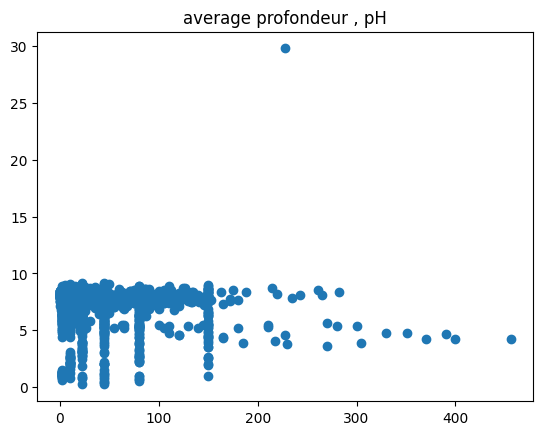

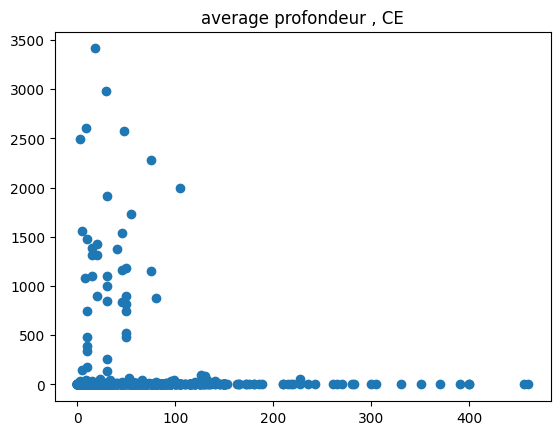

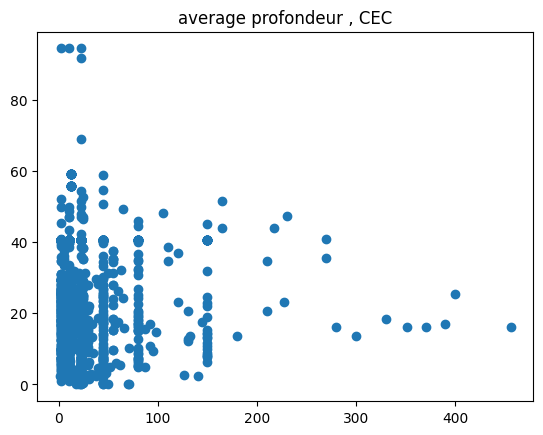

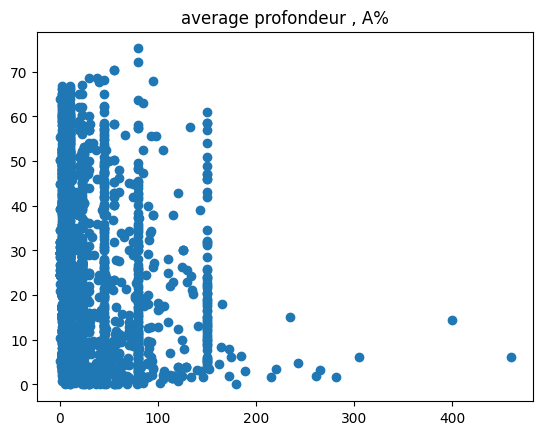

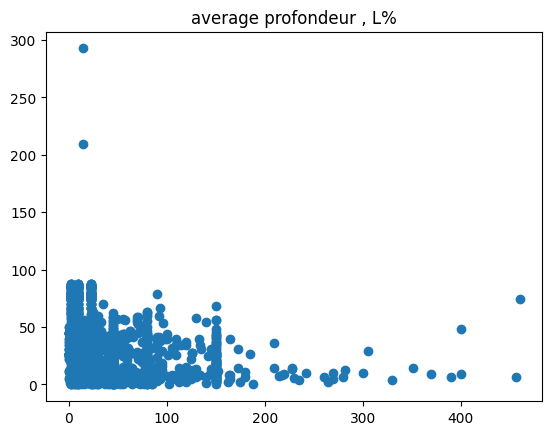

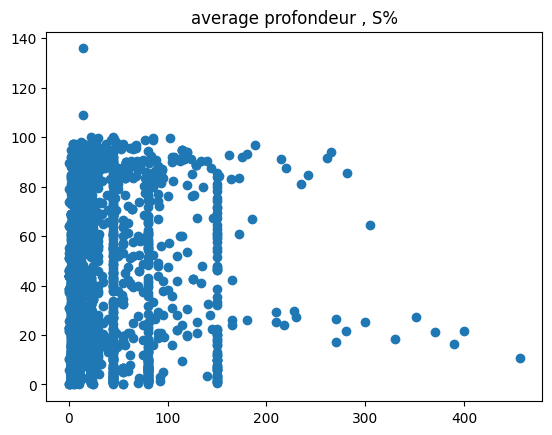

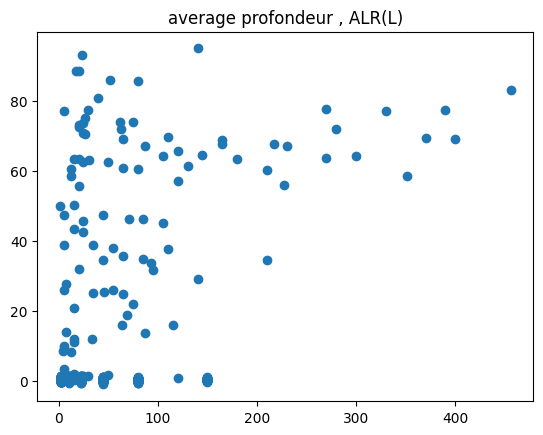

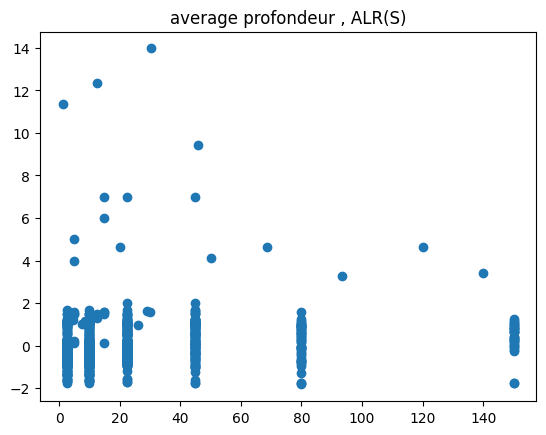

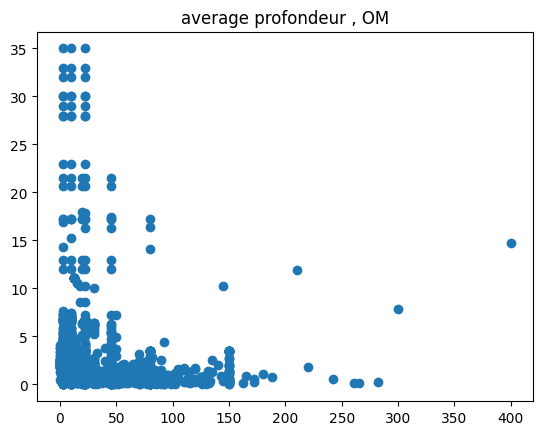

In [38]:
for i in df.columns[5:]:
    plt.scatter(df["average profondeur"] , df[i])
    plt.title(f"average profondeur , {i}")
    plt.show()

In [17]:
print(df.isnull().sum()) 
print(df[df.isnull().any(axis=1)])

X                        0
Y                        0
UD                       0
LD                       0
average profondeur       0
pH                     240
CE                     293
CEC                   1067
A%                     384
L%                     386
S%                     333
ALR(L)                1430
ALR(S)                1512
OM                     496
dtype: int64
         X      Y    UD     LD  average profondeur        pH        CE  CEC  \
0     1.32  36.20   0.0    5.0                 2.5  1.316667  0.233333  NaN   
1     1.32  36.20   5.0   15.0                10.0  2.633333  0.466667  NaN   
2     1.32  36.20  15.0   30.0                22.5  3.950000  0.700000  NaN   
3     1.32  36.20  30.0   60.0                45.0  5.333333  0.333333  NaN   
4     1.32  36.20  60.0  100.0                80.0  2.666667  0.166667  NaN   
...    ...    ...   ...    ...                 ...       ...       ...  ...   
2700  2.43  27.19   0.0    8.0                 4.0  7.39

In [18]:
import pandas as pd
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

numeric_df = df.select_dtypes(include=['float64', 'int64'])
scaler = StandardScaler()
scaled_data = scaler.fit_transform(numeric_df)

imputer = KNNImputer(n_neighbors=5)
imputed_array = imputer.fit_transform(scaled_data)
real_values = scaler.inverse_transform(imputed_array)
df[numeric_df.columns] = real_values

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2632 entries, 0 to 2704
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   X                   2632 non-null   float64
 1   Y                   2632 non-null   float64
 2   UD                  2632 non-null   float64
 3   LD                  2632 non-null   float64
 4   average profondeur  2632 non-null   float64
 5   pH                  2632 non-null   float64
 6   CE                  2632 non-null   float64
 7   CEC                 2632 non-null   float64
 8   A%                  2632 non-null   float64
 9   L%                  2632 non-null   float64
 10  S%                  2632 non-null   float64
 11  ALR(L)              2632 non-null   float64
 12  ALR(S)              2632 non-null   float64
 13  OM                  2632 non-null   float64
dtypes: float64(14)
memory usage: 308.4 KB


C:\Users\abdo7\AppData\Local\Temp\ipykernel_21828\1634113071.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[numeric_df.columns] = real_values


In [20]:
df.to_csv("../results/Finals.csv")